In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from numpy.linalg import inv
from numpy.linalg import pinv
import cv2
import itertools as it
import os 

In [2]:
np.show_config()

openblas64__info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['openblas\\lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BLAS_SYMBOL_SUFFIX', '64_'), ('HAVE_BLAS_ILP64', None)]
    runtime_library_dirs = ['openblas\\lib']
blas_ilp64_opt_info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['openblas\\lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BLAS_SYMBOL_SUFFIX', '64_'), ('HAVE_BLAS_ILP64', None)]
    runtime_library_dirs = ['openblas\\lib']
openblas64__lapack_info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['openblas\\lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BLAS_SYMBOL_SUFFIX', '64_'), ('HAVE_BLAS_ILP64', None), ('HAVE_LAPACKE', None)]
    runtime_library_dirs = ['openblas\\lib']
lapack_ilp64_opt_info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['openblas\\lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BL

# Spectrum Transfer Model

In [3]:
st_extend_20 = 0
st_extend_21 = 1
st_extend_30 = 2

class SpectrumTransfer:
    
    def __init__(self):
        self.extend_mode = 0
        self.pca_eigenvectors = None
        self.pca_mean = None
        self.M = None
        self.TransM = None
        self.TransMin = 0.0
        self.TransMax = 1.0
        
    def get_extend_color(self, src_rgb):
        
        extend = None

        if self.extend_mode == 0:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2)])
        elif self.extend_mode == 1:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2]])
        elif self.extend_mode == 2:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2], np.power(src_rgb[:,0],3), np.power(src_rgb[:,1],3), np.power(src_rgb[:,2],3)])

        return extend
    
    def prepare(self):
        self.TransM = np.dot(self.M.T, self.pca_eigenvectors)
        return
     
    def train(self, extend_mode, train_spec, train_color, pca_comps=6):
        self.extend_mode = extend_mode
        
        pca = PCA(n_components=pca_comps, whiten=False)
        pca.fit(train_spec)
        
        self.pca_eigenvectors = pca.components_
        self.pca_mean = pca.mean_

        trans_pca_a = pca.transform(train_spec)
        trans_extend_c = self.get_extend_color(train_color)

        self.M = np.dot(trans_pca_a.T, pinv(trans_extend_c))

        self.prepare()
        
        c = np.arange(256)
        all_color = np.array(np.meshgrid(c, c, c)).T.reshape(-1,3)

        self.TransMin = 0.0
        self.TransMax = 1.0
        
#         min_v = 100.0
#         max_v = -100.0

#         split_num = 64
#         batch_size = int(all_color.shape[0] / split_num)

#         for n in range(64):
#             test_c = all_color[n * batch_size: (n+1) *batch_size, :]
#             test_s = self.transfer(test_c)
#             batch_min = np.min(test_s)
#             batch_max = np.max(test_s)

#             min_v = min(min_v, batch_min)
#             max_v = max(max_v, batch_max)

#         self.TransMin = min_v
#         self.TransMax = max_v
        
        return
    
    def save(self, setup_file):
        np.savez(setup_file, a=self.M, b=self.pca_eigenvectors, c=self.pca_mean, d=np.array([self.TransMin,self.TransMax]), e=np.array([self.extend_mode]))

        
    def save_files(self, setup_path):
        np.save(os.path.join(setup_path, "spec_a.npy"), self.M)
        np.save(os.path.join(setup_path, "spec_b.npy"), self.pca_eigenvectors)
        np.save(os.path.join(setup_path, "spec_c.npy"), self.pca_mean)
        np.save(os.path.join(setup_path, "spec_d.npy"), np.array([self.TransMin,self.TransMax]))
        np.save(os.path.join(setup_path, "spec_e.npy"), np.array([self.extend_mode]))
        
    def load(self, setup_file):
        weight = np.load(setup_file)
        
        self.M = weight["a"]
        self.pca_eigenvectors = weight["b"]
        self.pca_mean = weight["c"]
        
#         self.TransMin = weight['d'][0]
#         self.TransMax = weight['d'][1]
        
        self.extend_mode = weight['e'][0]
        
        self.prepare()
        
        return
 
    def transfer1D(self, src_data):
        
        src_data = src_data.astype(np.float32)

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)

        return tar_sepc
    
    def transfer(self, src_data):
        
        src_data = src_data.astype(np.float32)
        
        src_shape = src_data.shape

        if len(src_shape) >= 3:
            src_data = src_data.reshape(-1, src_shape[-1])

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean

        if len(src_shape) >= 3:
            tar_sepc = tar_sepc.reshape(src_shape[0:-1] + tuple([self.pca_mean.shape[0]]))
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)
        
        return tar_sepc

# Train new model and save

In [4]:
# datasets
file_train_spec_data = '24_color_spectrum.txt'
file_train_color_data = '24_color_sRGB.txt'

train_spec = np.loadtxt(file_train_spec_data).T
print('train_spec shape', train_spec.shape)

train_color = np.loadtxt(file_train_color_data).T
print('train_color shape', train_color.shape)

# create model
new_md = SpectrumTransfer()

# train model
new_md.train(st_extend_20, train_spec, train_color)

# test transfer
trans_data = np.array([[124,200,255]])
trans_spec = new_md.transfer(trans_data)

print('trans_data shape', trans_data.shape)
print('trans_spec shape', trans_spec.shape)

# save model
new_md.save("weight.npz")

new_md.save_files("")

train_spec shape (24, 401)
train_color shape (24, 3)
trans_data shape (1, 3)
trans_spec shape (1, 401)


# Load model and use

In [5]:
# create model
transfer = SpectrumTransfer()

# load model
transfer.load("weight.npz")

# test transfer
trans_data = np.array([[124,200,255]])
trans_spec = transfer.transfer(trans_data)

print('trans_data shape', trans_data.shape)
print('trans_spec shape', trans_spec.shape)

trans_data shape (1, 3)
trans_spec shape (1, 401)


# Test color transfer and show

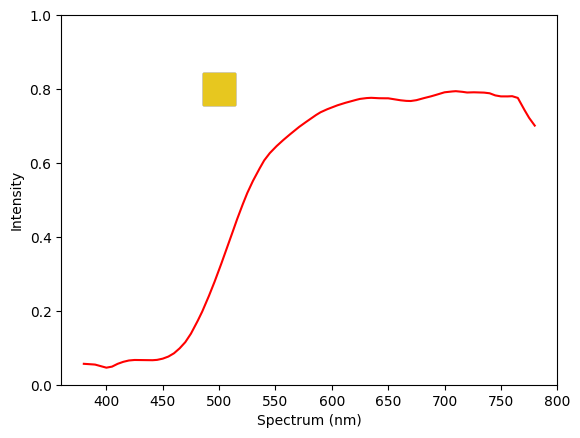

In [6]:
# define test color
test_user_c = np.array([[231,199,31]])

# transfer
test_user_sepc = transfer.transfer(test_user_c)

# display test color transfer result
spec_start = 380
spec_end = 780

x = np.arange(spec_start, spec_end + 1, 1)
y1 = test_user_sepc[0]

plt.ylim(0.0, 1.0)
plt.plot(x, y1, 'r')

now_c = test_user_c[0]
plt.scatter([500], [0.8], marker='s', s = 550, color = (0,0,0))
plt.scatter([500], [0.8], marker='s', s = 500, color = (now_c[0]/255, now_c[1]/255, now_c[2]/255))
 
plt.xlabel('Spectrum (nm)')
plt.ylabel('Intensity')

plt.show()

# Test Image Transfer

In [7]:
# load image
test_img = cv2.imread('Img0000000026.jpg')

# opencv default format is BGR
# most transfer to RGB
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

print('test_img shape', test_img.shape)

error: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:196: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


In [ ]:
# transfer
test_img_spec = transfer.transfer(test_img)

print('test_img_spec shape', test_img_spec.shape)

test_img_spec shape (501, 575, 401)


In [8]:
aaa = test_img_spec[:,:,::40].astype('float32')

NameError: name 'test_img_spec' is not defined

In [9]:
np.max(aaa)
np.min(aaa)

NameError: name 'aaa' is not defined

In [8]:
img_h,img_w,img_c = test_img.shape
print('image size as below, makesure set position in range')
print('width ', img_w)
print('height', img_h)

image size as below, makesure set position in range
width  575
height 501


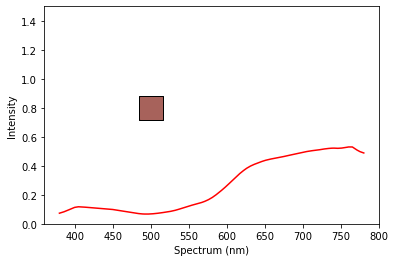

In [11]:
# define test position
pos_x = 146
pos_y =168

# display test position color transfer result
spec_start = 380
spec_end = 780

x = np.arange(spec_start, spec_end + 1, 1)
y1 = test_img_spec[pos_y, pos_x]

plt.ylim(0.0, 1.5)
plt.plot(x, y1, 'r')

now_c = test_img[pos_y, pos_x]
plt.scatter([500], [0.8], marker='s', s = 550, color = (0,0,0))
plt.scatter([500], [0.8], marker='s', s = 500, color = (now_c[0]/255, now_c[1]/255, now_c[2]/255))
 
plt.xlabel('Spectrum (nm)')
plt.ylabel('Intensity')

plt.show()

In [10]:
np.save('spectrum.npy', test_img_spec);

NameError: name 'test_img_spec' is not defined

In [11]:
trans_spec = transfer.transfer(train_color)
trans_spec.shape

np.savetxt("py_spec.csv", trans_spec.T, delimiter=",")